In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import re
from tqdm import trange

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import LogLocator

import matplotlib as mpl

mpl.rcParams.update(
     {# Use mathtext, not LaTeX
     'text.usetex': False,
     'axes.formatter.use_mathtext': True,
     # Set the fonts
     'font.family': 'STIXGeneral',
     'mathtext.fontset': 'cm',
     # Use ASCII minus
     'axes.unicode_minus': False,
    'axes.linewidth':1.5
})



rsun = 6.96e10
G = 6.67e-8
msun = 1.989e33
yr_to_sec = 3.154e7
lsun = 3.85e33
kb = 1.381e-16
mh = 1.67e-24

# ------------------------------------
# -------------- TESTS ---------------
# ------------------------------------

In [2]:
#history_kolb_1 = pd.read_csv('./chromosphere_accretion_3/LOGS1_1.5m1_0.6m2_200p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_kolbdefault/history.data', skiprows = 5, delim_whitespace=True)
#history_kolb_2 = pd.read_csv('./chromosphere_accretion_3/LOGS1_1.5m1_0.6m2_750p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_kolbrevised/history.data', skiprows = 5, delim_whitespace=True)
#history_kolb_3 = pd.read_csv('./chromosphere_accretion_3/LOGS1_1.5m1_0.6m2_2000p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_kolbrevised/history.data', skiprows = 5, delim_whitespace=True)

history_kolb_1 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_ritter_p200/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_kolb_2 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_ritter_p750/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_kolb_3 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_ritter_p2000/LOGS1/history.data', skiprows = 5, delim_whitespace=True)

print(np.array(history_kolb_2.columns))

kolb_histories = [history_kolb_1, history_kolb_2, history_kolb_3]


['model_number' 'num_zones' 'star_age' 'log_dt' 'star_mass' 'log_xmstar'
 'log_abs_mdot' 'mass_conv_core' 'conv_mx1_top' 'conv_mx1_bot'
 'conv_mx2_top' 'conv_mx2_bot' 'mx1_top' 'mx1_bot' 'mx2_top' 'mx2_bot'
 'log_LH' 'log_LHe' 'log_LZ' 'log_Lnuc' 'pp' 'cno' 'tri_alpha'
 'epsnuc_M_1' 'epsnuc_M_2' 'epsnuc_M_3' 'epsnuc_M_4' 'epsnuc_M_5'
 'epsnuc_M_6' 'epsnuc_M_7' 'epsnuc_M_8' 'he_core_mass' 'co_core_mass'
 'one_core_mass' 'fe_core_mass' 'neutron_rich_core_mass' 'log_Teff'
 'log_L' 'log_R' 'log_g' 'v_div_csound_surf' 'log_cntr_P' 'log_cntr_Rho'
 'log_cntr_T' 'center_mu' 'center_ye' 'center_abar' 'center_h1'
 'center_he4' 'center_c12' 'center_o16' 'surface_c12' 'surface_o16'
 'total_mass_h1' 'total_mass_he4' 'num_retries' 'num_iters' 'egrav_env'
 'energy_env' 'egas_from_Pgas_env' 'erad_from_Prad_env' 'ekin_env'
 'rho_surf' 'vcon_surf' 'rcon' 'taucon' 'Mcon_surf' 'rhocon_surf'
 'cs_surf' 'Peos_surf' 'T_surf' 'model_number.1' 'age' 'period_days'
 'binary_separation' 'v_orb_1' 'v_orb_2' 'rl_1'

In [3]:
for history in kolb_histories:

    print('Period: ',history.period_days.values[-1])
    print('Donor Mass: ',history.star_1_mass.values[-1])
    print('Max Mdot: ',np.max(history.lg_mtransfer_rate.values))
    print('')

Period:  326.6909555561221
Donor Mass:  0.3897849421770268
Max Mdot:  -0.32491693479537526

Period:  701.4208919327933
Donor Mass:  0.5515822657469419
Max Mdot:  -1.099051506674718

Period:  7227.297527654569
Donor Mass:  0.5700163647841263
Max Mdot:  -5.629937370214802



In [3]:
#history_chrom_1 = pd.read_csv('./chromosphere_accretion_3/LOGS1_1.5m1_0.6m2_200p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_revisedvslim/history.data', skiprows = 5, delim_whitespace=True)
#history_chrom_2 = pd.read_csv('./chromosphere_accretion_4/LOGS1_1.5m1_0.6m2_750p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_revisedvslim/history.data', skiprows = 5, delim_whitespace=True)
#history_chrom_3 = pd.read_csv('./chromosphere_accretion_4/LOGS1_1.5m1_0.6m2_2100p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi/history.data', skiprows = 5, delim_whitespace=True)

history_chrom_1 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_full_chrom_p200/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_chrom_2 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_full_chrom_p750/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_chrom_3 = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_full_chrom_p2000/LOGS1/history.data', skiprows = 5, delim_whitespace=True)

chrom_histories = [history_chrom_1, history_chrom_2, history_chrom_3]


In [5]:
for history in chrom_histories:

    print('Period: ',history.period_days.values[-1])
    print('Donor Mass: ',history.star_1_mass.values[-1])
    print('Max Mdot: ',np.max(history.lg_mtransfer_rate.values))
    print('')

Period:  355.89327573535195
Donor Mass:  0.3739288652046158
Max Mdot:  -0.5519640744546566

Period:  1008.138581854692
Donor Mass:  0.4321350209317808
Max Mdot:  -1.569445195639749

Period:  2100.138224949376
Donor Mass:  0.5456781538303075
Max Mdot:  -4.359569825367827



In [4]:
#history_chrom_1_0p5fcon = pd.read_csv('./chromosphere_accretion_4/LOGS1_1.5m1_0.6m2_200p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_0.5fcon/history.data', skiprows = 5, delim_whitespace=True)
#history_chrom_2_0p5fcon = pd.read_csv('./chromosphere_accretion_4/LOGS1_1.5m1_0.6m2_750p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_0.5fcon/history.data', skiprows = 5, delim_whitespace=True)
#history_chrom_3_0p5fcon = pd.read_csv('./chromosphere_accretion_4/LOGS1_1.5m1_0.6m2_2000p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_0.5fcon_revisedvslim/history.data', skiprows = 5, delim_whitespace=True)

history_chrom_1_0p5fcon = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_red_chrom_p200/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_chrom_2_0p5fcon = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_red_chrom_p750/LOGS1/history.data', skiprows = 5, delim_whitespace=True)
history_chrom_3_0p5fcon = pd.read_csv('/resnick/groups/elbadry_lab/sbhatta2/mesa-r24.03.1/binary/chromosphere_paper/chromosphere_accretion_red_chrom_p2000/LOGS1/history.data', skiprows = 5, delim_whitespace=True)

chrom_histories_0p5fcon = [history_chrom_1_0p5fcon, history_chrom_2_0p5fcon, history_chrom_3_0p5fcon]

In [7]:
for history in chrom_histories_0p5fcon:

    print('Period: ',history.period_days.values[-1])
    print('Donor Mass: ',history.star_1_mass.values[-1])
    print('Max Mdot: ',np.max(history.lg_mtransfer_rate.values))
    print('')

Period:  331.48190506295515
Donor Mass:  0.3871148674271364
Max Mdot:  -0.34968788280425395

Period:  696.9058212997035
Donor Mass:  0.5510339909965272
Max Mdot:  -1.1687620892202435

Period:  6066.643055969408
Donor Mass:  0.5710552506137073
Max Mdot:  -4.58936214148908



"\nfor i in range(Ncol):\n    ax = fig.add_subplot(gs[1, i])\n\n    history = kolb_histories[i]\n    rbyrl = (10**history.log_R.values)/history.rl_1.values\n\n    mask1 = (rbyrl>0.3)\n    index_rbyrl = np.arange(len(rbyrl))\n    if sum(rbyrl>=1.0)>0:\n        mask2 = (index_rbyrl<np.where(rbyrl>=rdbyrl_lim)[0][0])\n    else:\n        mask2 = np.repeat(True, len(rbyrl))\n    select = mask1 & mask2\n\n    ax.plot(rbyrl[select], (history.star_2_mass.values[select] - history.star_2_mass.values[0])/(1 - beta))\n\n    history = chrom_histories[i]\n    rbyrl = (10**history.log_R.values)/history.rl_1.values\n\n    mask1 = (rbyrl>0.3)\n    index_rbyrl = np.arange(len(rbyrl))\n    if sum(rbyrl>=1.0)>0:\n        mask2 = (index_rbyrl<np.where(rbyrl>=rdbyrl_lim)[0][0])\n    else:\n        mask2 = np.repeat(True, len(rbyrl))\n    select = mask1 & mask2\n\n    ax.plot(rbyrl[select], (history.star_2_mass.values[select] - history.star_2_mass.values[0])/(1 - beta))\n\n    ax.tick_params(which='both',dir

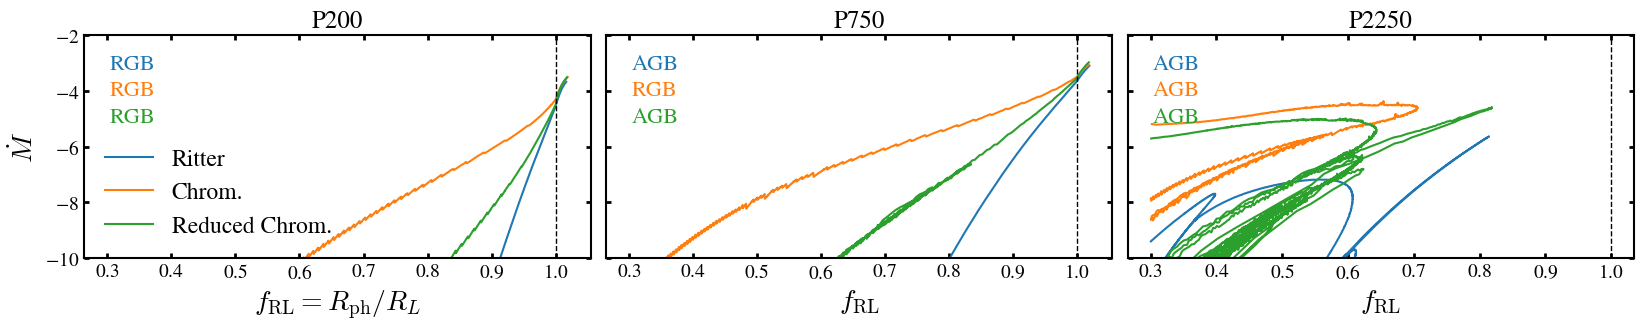

In [ ]:
Ncol = len(kolb_histories)
beta = 0.75

N = 4  # number of rows (change as needed)

fig = plt.figure(figsize=(20, 3*N))
gs = GridSpec(nrows=N, ncols=Ncol, figure=fig, hspace=0.05, wspace = 0.03)

sim_pers = ['P200', 'P750', 'P2250']

rdbyrl_lim = 1.02

ritter_mt_phase = ['RGB', 'AGB', 'AGB']
chrom_mt_phase = ['RGB', 'RGB', 'AGB']
chrom0p5_mt_phase = ['RGB', 'AGB', 'AGB']

for i in range(Ncol):
    ax = fig.add_subplot(gs[0, i])

    history = kolb_histories[i]
    rbyrl = (10**history.log_R.values)/history.rl_1.values
    #select = (rbyrl>0.4) & (history.star_mass.values>0.7)
    mask1 = (rbyrl>0.3)
    index_rbyrl = np.arange(len(rbyrl))
    if sum(rbyrl>=1.0)>0:
        mask2 = (index_rbyrl<np.where(rbyrl>=rdbyrl_lim)[0][0])
    else:
        mask2 = np.repeat(True, len(rbyrl))
    select = mask1 & mask2

    if i==0:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select], label = r'Ritter')
    else:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select])

    history = chrom_histories[i]
    rbyrl = (10**history.log_R.values)/history.rl_1.values
    #select = (rbyrl>0.4) & (history.star_mass.values>0.7)
    mask1 = (rbyrl>0.3)
    index_rbyrl = np.arange(len(rbyrl))
    if sum(rbyrl>=1.0)>0:
        mask2 = (index_rbyrl<np.where(rbyrl>=rdbyrl_lim)[0][0])
    else:
        mask2 = np.repeat(True, len(rbyrl))
    select = mask1 & mask2
    
    if i==0:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select], label = r'Chrom.')
        ax.legend(loc = 'lower left', fontsize=17, framealpha = 0.0, ncols = 1)
    else:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select])

    
    history = chrom_histories_0p5fcon[i]
    rbyrl = (10**history.log_R.values)/history.rl_1.values
    #select = (rbyrl>0.4) & (history.star_mass.values>0.7)
    mask1 = (rbyrl>0.3)
    index_rbyrl = np.arange(len(rbyrl))
    if sum(rbyrl>=1.0)>0:
        mask2 = (index_rbyrl<np.where(rbyrl>=rdbyrl_lim)[0][0])
    else:
        mask2 = np.repeat(True, len(rbyrl))
    select = mask1 & mask2
    
    if i==0:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select], label = r'Reduced Chrom.',
                c = 'C2', linestyle = '-')
        ax.legend(loc = 'lower left', fontsize=17, framealpha = 0.0, ncols = 1)
    else:
        ax.plot(rbyrl[select], history.lg_mtransfer_rate.values[select],
                c = 'C2', linestyle = '-')
    

    ax.set_ylim(-10, -2)

    if i==0:
        ax.tick_params(which='both',direction='in',top=True,right=True,labelsize=14,labelbottom = True, width=2)
        ax.set_ylabel(r'$\dot{M}$', fontsize = 20)
        ax.set_xlabel(r'$f_{\rm RL}=R_{\rm ph}/R_L$', fontsize = 20)
    else:
        ax.tick_params(which='both',direction='in',top=True,right=True,labelsize=14,labelbottom = True, width=2,
                       labelleft = False)
        ax.set_xlabel(r'$f_{\rm RL}$', fontsize = 20)
        
    ax.set_title(r'{}'.format(sim_pers[i]), fontsize = 18)

    ax.axvline(1.0, c='k', linestyle = '--', linewidth = 1.0)

    ax.text(0.05, 0.85, ritter_mt_phase[i], fontsize = 16, c='C0', transform = ax.transAxes)
    ax.text(0.05, 0.73, chrom_mt_phase[i], fontsize = 16, c='C1', transform = ax.transAxes)
    ax.text(0.05, 0.61, chrom0p5_mt_phase[i], fontsize = 16, c='C2', transform = ax.transAxes)


#plt.savefig("./chromosphere_figs/quants_v_rdbyrl_revised.png",dpi=200,bbox_inches='tight')



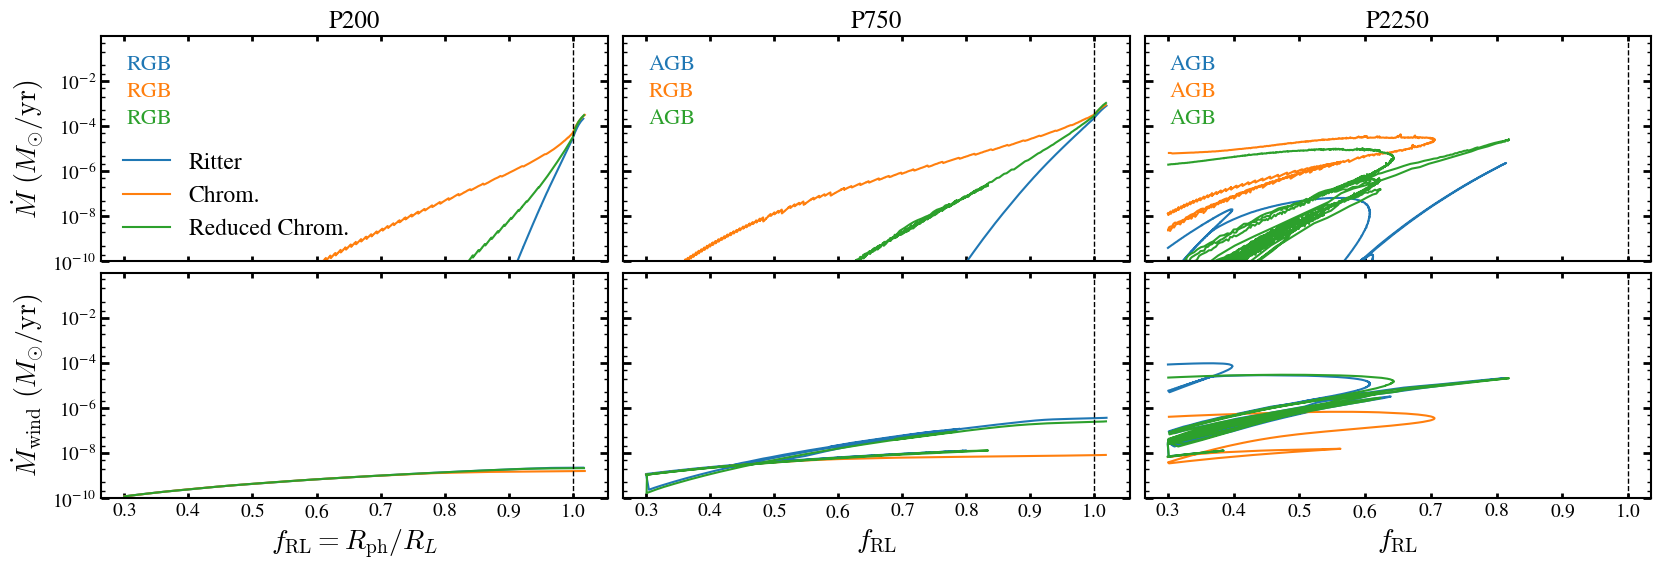

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import LogLocator, NullFormatter

Ncol = len(kolb_histories)
N = 2

fig = plt.figure(figsize=(20, 3 * N))
gs = GridSpec(nrows=N, ncols=Ncol, figure=fig, hspace=0.05, wspace=0.03)

sim_pers = ['P200', 'P750', 'P2250']
rdbyrl_lim = 1.02

ritter_mt_phase = ['RGB', 'AGB', 'AGB']
chrom_mt_phase = ['RGB', 'RGB', 'AGB']
chrom0p5_mt_phase = ['RGB', 'AGB', 'AGB']

models = (
    (kolb_histories, 'Ritter', 'C0', ritter_mt_phase),
    (chrom_histories, 'Chrom.', 'C1', chrom_mt_phase),
    (chrom_histories_0p5fcon, 'Reduced Chrom.', 'C2', chrom0p5_mt_phase),
)

for i in range(Ncol):
    ax_mt = fig.add_subplot(gs[0, i])
    ax_wind = fig.add_subplot(gs[1, i], sharex=ax_mt)

    for model_index, (histories, label, color, phases) in enumerate(models):
        history = histories[i]
        rbyrl = (10.0 ** history.log_R.values) / history.rl_1.values

        # Use the same selected models in both panels, stopping before the
        # first crossing of rdbyrl_lim, if such a crossing exists.
        select = rbyrl > 0.3
        crossings = np.flatnonzero(rbyrl >= rdbyrl_lim)
        if crossings.size:
            select &= np.arange(len(rbyrl)) < crossings[0]

        for ax, log_rate in (
            (ax_mt, history.lg_mtransfer_rate.values),
            (ax_wind, history.lg_wind_mdot_1.values),
        ):
            ax.plot(
                rbyrl[select],
                10.0 ** log_rate[select],
                c=color,
                label=label if i == 0 else None,
            )

        ax_mt.text(
            0.05, 0.85 - 0.12 * model_index, phases[i],
            fontsize=16, c=color, transform=ax_mt.transAxes,
        )

    for ax in (ax_mt, ax_wind):
        ax.set_yscale('log')
        ax.set_ylim(1e-10, 0.9999)
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=6))
        ax.yaxis.set_minor_locator(
            LogLocator(base=10, subs=(2, 5), numticks=100)
        )
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(
            which='both', direction='in', top=True, right=True,
            labelsize=14, width=2, labelleft=(i == 0),
        )
        ax.tick_params(axis='y', which='major', length=6)
        ax.tick_params(axis='y', which='minor', length=3, width=1)
        ax.axvline(1.0, c='k', linestyle='--', linewidth=1.0)

    ax_mt.tick_params(which='both', labelbottom=False)
    ax_mt.set_title(sim_pers[i], fontsize=18)

    if i == 0:
        ax_mt.set_ylabel(r'$\dot{M}~(M_{\odot}/{\rm yr})$', fontsize=20)
        ax_wind.set_ylabel(
            r'$\dot{M}_{\rm wind}~(M_{\odot}/{\rm yr})$', fontsize=20
        )
        ax_mt.legend(loc='lower left', fontsize=17, framealpha=0.0, ncols=1)
        ax_wind.set_xlabel(r'$f_{\rm RL}=R_{\rm ph}/R_L$', fontsize=20)
    else:
        ax_wind.set_xlabel(r'$f_{\rm RL}$', fontsize=20)

# plt.show()
plt.savefig(
     './chromosphere_figs/quants_v_rdbyrl.png',
     dpi=200, bbox_inches='tight',
 )

In [10]:
x_ranges_gyr_by_col = [
    [(2.445, 2.4479), (2.563, 2.568)],  # column 0 / P200
    [(2.4478, 2.4500), (2.5651, 2.5655)],  # column 1 / P750
    [(2.4478, 2.4515), (2.5655, 2.567)],  # column 2 / P2000
]

# Edit one sub-list per column to set the visual axis proportions manually.
# The number of ratios must match the number of ranges in that column.
# Example: [2, 1] makes the left panel twice as wide as the right panel.
# Use None for a column to scale its panels by their x-range spans instead.
x_width_ratios_by_col = [
    [1.0, 0.2],  # column 0 / P200
    [1.0, 0.5],  # column 1 / P750
    [0.4, 1.0],  # column 2 / P2000
]

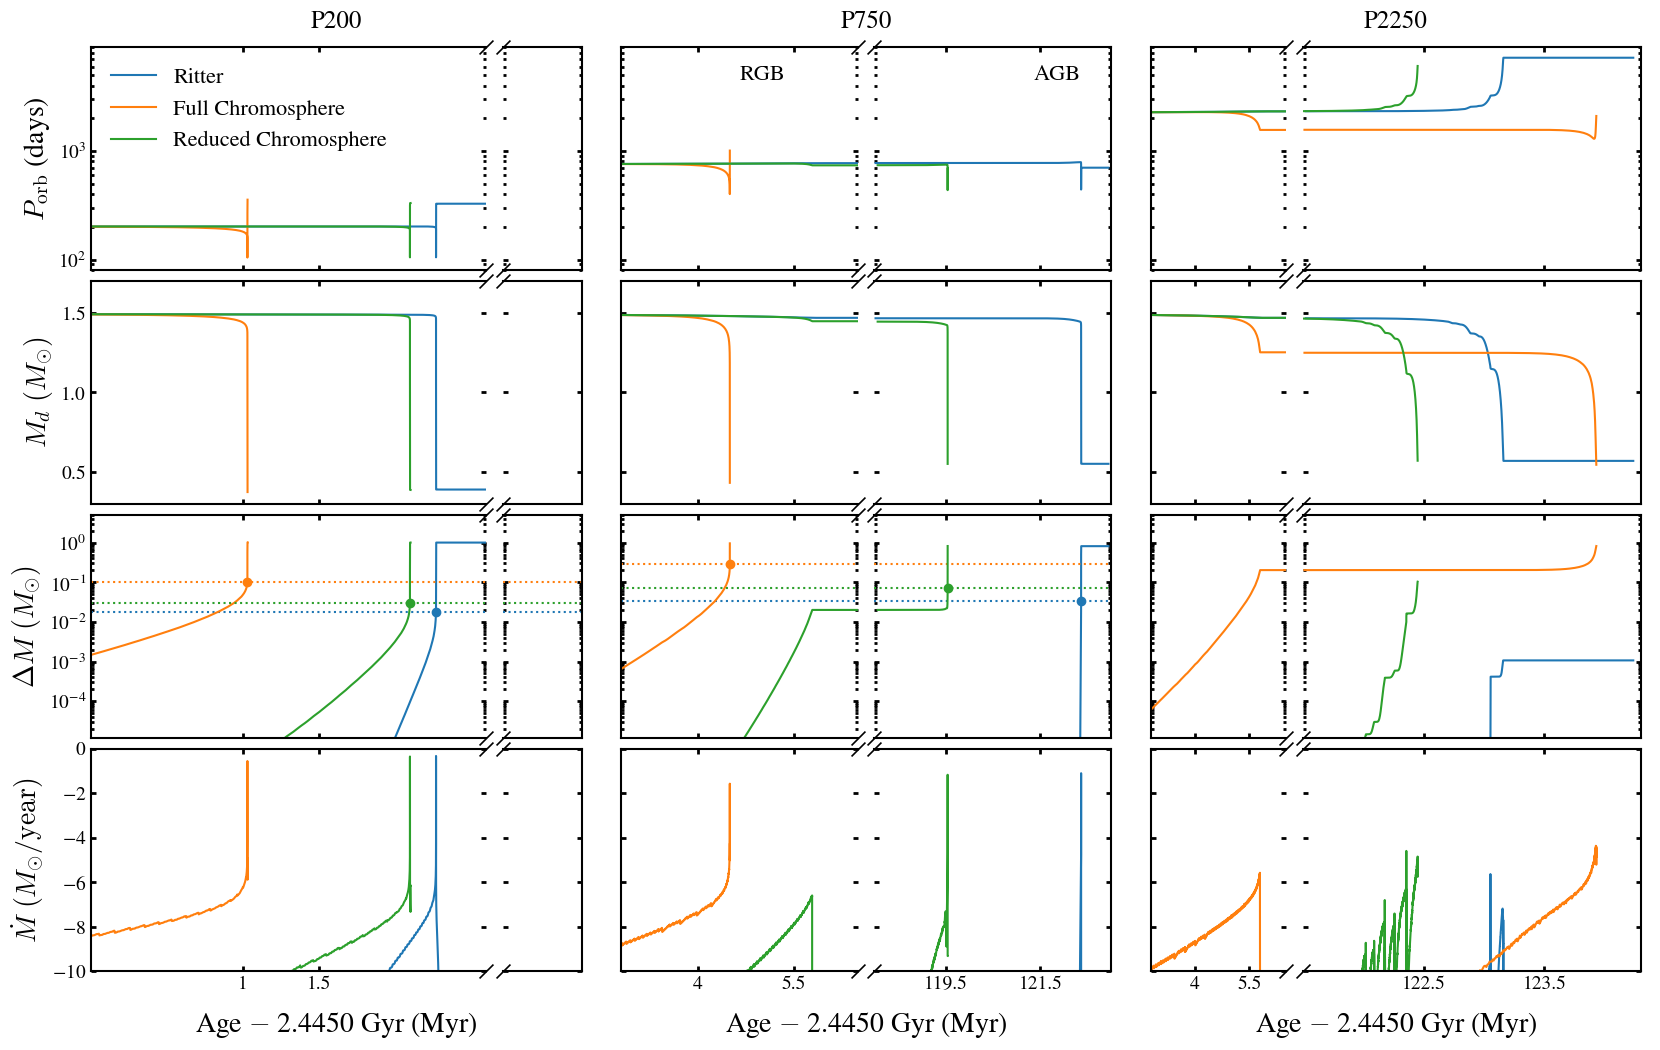

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

Ncol = len(kolb_histories)
beta = 0.75

# Active rows:
# 0: orbital period
# 1: donor radius
# 2: transferred mass
# 3: mass-transfer rate
N = 4

fig = plt.figure(figsize=(20, 3 * N))
gs = GridSpec(nrows=N, ncols=Ncol, figure=fig, hspace=0.05, wspace=0.08)

age_norm = 1e9
max_mdot_epoch = 0.0

# Edit one sub-list per column to change the kink/broken x-axis ranges.
# Values are in Gyr. Each column can use different ranges and even a different
# number of broken-axis panels.

'''
x_ranges_gyr_by_col = [
    [(2.445, 2.4479), (2.563, 2.568)],  # column 0 / P200
    [(2.4478, 2.4500), (2.5651, 2.5655)],  # column 1 / P750
    [(2.4478, 2.4515), (2.5655, 2.567)],  # column 2 / P2000
]

# Edit one sub-list per column to set the visual axis proportions manually.
# The number of ratios must match the number of ranges in that column.
# Example: [2, 1] makes the left panel twice as wide as the right panel.
# Use None for a column to scale its panels by their x-range spans instead.
x_width_ratios_by_col = [
    [1.0, 0.2],  # column 0 / P200
    [1.0, 0.5],  # column 1 / P750
    [0.4, 1.0],  # column 2 / P2000
]
'''

# Plot the x-axis as time since the first plotted age, in Myr.
x_start_gyr = min(lo for ranges in x_ranges_gyr_by_col for lo, hi in ranges)
x_axis_label = rf'Age $-$ {x_start_gyr:.4f} Gyr (Myr)'
x_tick_steps_myr = [0.5, 0.2, 0.1, 0.05]
x_tick_count = 2
x_tick_edge_padding_frac = 0.05


sim_pers = ['P200', 'P750', 'P2250']


class KinkAxes(list):
    """List of axes plus the x-ranges used to create them."""

    def __init__(self, axes, x_ranges_gyr):
        super().__init__(axes)
        self.x_ranges_gyr = x_ranges_gyr
        self.has_plotted_data = [False for _ in axes]


def get_column_x_ranges_gyr(col):
    """Return and validate the broken x-axis ranges for one column."""
    if col >= len(x_ranges_gyr_by_col):
        raise ValueError(
            f"Missing x_ranges_gyr_by_col entry for column {col}. "
            f"Expected {Ncol} column entries."
        )

    x_ranges_gyr = x_ranges_gyr_by_col[col]
    if len(x_ranges_gyr) == 0:
        raise ValueError(f"x_ranges_gyr_by_col[{col}] must contain at least one range.")

    for lo, hi in x_ranges_gyr:
        if hi <= lo:
            raise ValueError(
                f"Invalid x range ({lo}, {hi}) in x_ranges_gyr_by_col[{col}]."
            )

    return x_ranges_gyr


def get_column_width_ratios(col, x_ranges_gyr):
    """Return and validate the visual width ratios for one column."""
    if col >= len(x_width_ratios_by_col):
        raise ValueError(
            f"Missing x_width_ratios_by_col entry for column {col}. "
            f"Expected {Ncol} column entries."
        )

    width_ratios = x_width_ratios_by_col[col]
    if width_ratios is None:
        return [hi - lo for lo, hi in x_ranges_gyr]

    if len(width_ratios) != len(x_ranges_gyr):
        raise ValueError(
            f"x_width_ratios_by_col[{col}] has {len(width_ratios)} ratios, "
            f"but x_ranges_gyr_by_col[{col}] has {len(x_ranges_gyr)} ranges."
        )

    for ratio in width_ratios:
        if ratio <= 0:
            raise ValueError(
                f"Invalid width ratio {ratio} in x_width_ratios_by_col[{col}]."
            )

    return width_ratios


def age_gyr_to_plot_myr(age_gyr):
    """Convert an absolute age in Gyr to Myr after x_start_gyr."""
    return (np.asarray(age_gyr) - x_start_gyr) * 1e3


def myr_tick_label(value):
    """Format Myr tick labels without distracting trailing zeros."""
    if np.isclose(value, round(value), atol=0.05):
        return f"{value:.0f}"

    return f"{value:.1f}"


def nearest_before_max_index(arr, val, tol):
    
    max_idx = max(range(len(arr)), key=lambda i: arr[i])

    if max_idx == 0:
        return -1

    idx = min(range(max_idx), key=lambda i: abs(arr[i] - val))

    if abs(arr[idx] - val) <= tol:
        return idx

    return -1


def make_kink_axes(row, col):
    """Create broken-x axes inside one GridSpec cell."""
    x_ranges_gyr = get_column_x_ranges_gyr(col)
    width_ratios = get_column_width_ratios(col, x_ranges_gyr)

    subgs = gs[row, col].subgridspec(
        1,
        len(x_ranges_gyr),
        width_ratios=width_ratios,
        wspace=0.07,
    )

    axes = []
    for j, (lo, hi) in enumerate(x_ranges_gyr):
        if j == 0:
            ax = fig.add_subplot(subgs[0, j])
        else:
            ax = fig.add_subplot(subgs[0, j], sharey=axes[0])

        ax.set_xlim(*age_gyr_to_plot_myr([lo, hi]))

        if j > 0:
            ax.spines["left"].set_visible(False)
            ax.tick_params(left=True, labelleft=False)

        if j < len(x_ranges_gyr) - 1:
            ax.spines["right"].set_visible(False)

        axes.append(ax)

    add_kink_marks(axes)
    return KinkAxes(axes, x_ranges_gyr)


def choose_good_xticks(lo, hi):
    """Choose up to two readable interior ticks in Myr."""
    lo_myr, hi_myr = age_gyr_to_plot_myr([lo, hi])
    span = hi_myr - lo_myr
    if span <= 0:
        return np.array([])

    inner_lo = lo_myr + x_tick_edge_padding_frac * span
    inner_hi = hi_myr - x_tick_edge_padding_frac * span

    for tick_step_myr in x_tick_steps_myr:
        first_tick = np.ceil(inner_lo / tick_step_myr) * tick_step_myr
        last_tick = np.floor(inner_hi / tick_step_myr) * tick_step_myr

        if first_tick > last_tick:
            continue

        candidates = np.arange(
            first_tick,
            last_tick + 0.5 * tick_step_myr,
            tick_step_myr,
        )

        if len(candidates) <= x_tick_count:
            return candidates

        targets = np.linspace(lo_myr, hi_myr, x_tick_count + 2)[1:-1]
        remaining = candidates.tolist()
        ticks = []
        for target in targets:
            nearest_index = min(
                range(len(remaining)),
                key=lambda index: abs(remaining[index] - target),
            )
            ticks.append(remaining.pop(nearest_index))

        return np.array(sorted(ticks))

    return np.array([(lo_myr + hi_myr) / 2.0])


def set_good_xticks(ax, lo, hi):
    """Set readable interior x ticks for one broken-axis panel."""
    ticks = choose_good_xticks(lo, hi)
    ax.set_xticks(ticks)
    ax.set_xticklabels([myr_tick_label(tick) for tick in ticks])


def set_data_aware_xticks(axes, histories=None):
    """Set x ticks only on broken-axis panels that contain data."""
    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        if axes.has_plotted_data[j]:
            set_good_xticks(ax, lo, hi)
        else:
            ax.set_xticks([])
            ax.set_xticklabels([])


def add_kink_marks(axes, marker_size=10):
    """Draw uniform diagonal kink marks between neighboring broken axes."""
    for left_ax, right_ax in zip(axes[:-1], axes[1:]):


        # right edge of left axis
        left_ax.plot(
            [1, 1],
            [0, 1],
            transform=left_ax.transAxes,
            marker=[(-1, -1), (1, 1)],
            markersize=marker_size,
            linestyle="none",
            color="k",
            mec="k",
            mew=1.2,
            clip_on=False,
        )

        # left edge of right axis
        right_ax.plot(
            [0, 0],
            [0, 1],
            transform=right_ax.transAxes,
            marker=[(-1, -1), (1, 1)],
            markersize=marker_size,
            linestyle="none",
            color="k",
            mec="k",
            mew=1.2,
            clip_on=False,
        )


def plot_kinked(axes, history, y, **kwargs):
    """Plot only the selected x-ranges on the broken axes."""
    x_gyr = (history.star_age.values - max_mdot_epoch) / age_norm
    x_myr = age_gyr_to_plot_myr(x_gyr)
    y = np.asarray(y)

    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        select = (x_gyr >= lo) & (x_gyr <= hi)
        finite_select = select & np.isfinite(y)
        if np.count_nonzero(finite_select) >= 2:
            axes.has_plotted_data[j] = True

        ax.plot(x_myr[select], y[select], **kwargs)


def plot_scatter(axes, x_raw, y, **kwargs):
    """Plot only the selected x-ranges on the broken axes."""
    x_gyr = (x_raw - max_mdot_epoch) / age_norm
    x_myr = age_gyr_to_plot_myr(x_gyr)
    y = np.asarray(y)

    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        select = (x_gyr >= lo) & (x_gyr <= hi)
        finite_select = select & np.isfinite(y)
        if np.count_nonzero(finite_select) >= 1:
            axes.has_plotted_data[j] = True

        ax.scatter(x_myr[select], y[select], **kwargs)


def add_column_xlabel(row, col, xlabel):
    """Add one shared x-label under all kink axes in a column."""
    label_ax = fig.add_subplot(gs[row, col], frameon=False)
    label_ax.tick_params(
        labelcolor="none",
        top=False,
        bottom=False,
        left=False,
        right=False,
    )
    label_ax.set_xlabel(xlabel, fontsize=20, labelpad=10)



def add_column_title(row, col, title):
    """Add one shared title above all kink axes in a column."""
    title_ax = fig.add_subplot(gs[row, col], frameon=False)
    title_ax.tick_params(
        labelcolor="none",
        top=False,
        bottom=False,
        left=False,
        right=False,
    )
    title_ax.set_title(title, fontsize=18, pad=14)



def format_kinked_axes(
    axes,
    col_index,
    ylabel=None,
    xlabel=None,
    ylim=None,
    yscale=None,
    title=None,
    labelbottom=False,
):
    for j, ax in enumerate(axes):
        if ylim is not None:
            ax.set_ylim(*ylim)

        if yscale is not None:
            ax.set_yscale(yscale)

        ax.tick_params(
            which="both",
            direction="in",
            top=True,
            right=True,
            labelsize=14,
            labelbottom=labelbottom,
            width=2,
        )

        if col_index != 0 or j != 0:
            ax.tick_params(labelleft=False)

        if xlabel is not None:
            ax.set_xlabel(xlabel, fontsize=20)

    if ylabel is not None and col_index == 0:
        axes[0].set_ylabel(ylabel, fontsize=20)



# Row 0: orbital period
for i in range(Ncol):
    axes = make_kink_axes(0, i)

    if i==1:
        axes[0].text(age_gyr_to_plot_myr(2.44965), 4500, 'RGB', fontsize = 16)
        axes[1].text(age_gyr_to_plot_myr(2.56635), 4500, 'AGB', fontsize = 16)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C0",
        label = 'Ritter'
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C1",
        label = r'Full Chromosphere'
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C2",
        label = r'Reduced Chromosphere'
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$P_{\rm orb}$ (days)',
        ylim=(80, 9000),
        yscale="log",
        title=r'{}'.format(sim_pers[i]),
        labelbottom=False,
    )

    add_column_title(0, i, r'{}'.format(sim_pers[i]))

    if i==0:
        axes[0].legend(loc = 'upper left', fontsize = 16, framealpha = 0.0)

'''
# Row 1: donor radius
for i in range(Ncol):
    axes = make_kink_axes(1, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        10**history.log_R.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        10**history.log_R.values,
        c="C1",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$R_d~(R_{\odot})$',
        ylim=(0, 450),
        labelbottom=False,
    )
'''

# Row 2: donor mass
for i in range(Ncol):
    axes = make_kink_axes(1, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C1",
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C2",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$M_d~(M_{\odot})$',
        ylim=(0.3, 1.7),
        labelbottom=False,
    )


# Row 3: cumulative transferred mass
for i in range(Ncol):
    axes = make_kink_axes(2, i)

    history = kolb_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    

    plot_kinked(
        axes,
        history,
        y,
        c="C0",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C0",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C0')
        axes[1].axhline(ce_y, linestyle = ':', c='C0')

    history = chrom_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)
    plot_kinked(
        axes,
        history,
        y,
        c="C1",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C1",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C1')
        axes[1].axhline(ce_y, linestyle = ':', c='C1')

    
    history = chrom_histories_0p5fcon[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)
    plot_kinked(
        axes,
        history,
        y,
        c="C2",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C2",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C2')
        axes[1].axhline(ce_y, linestyle = ':', c='C2')
    

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\Delta M~(M_{\odot})$',
        ylim=(1.2e-5, 5),
        yscale="log",
        labelbottom=False,
    )

'''
# Row 4: cumulative transferred carbon mass
for i in range(Ncol):
    axes = make_kink_axes(4, i)

    history = kolb_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    deltay = np.diff(y)
    deltamc = np.diff(y) * (history.surface_c12.values[1:]+history.surface_c12.values[:-1])/2.0
    cmass_transferred = np.cumsum(deltamc)
    cmass_transferred = np.array([0] + cmass_transferred.tolist())

    plot_kinked(
        axes,
        history,
        cmass_transferred,
        c="C0",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.01)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([cmass_transferred[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C0",
        )

    history = chrom_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    deltay = np.diff(y)
    deltamc = np.diff(y) * (history.surface_c12.values[1:]+history.surface_c12.values[:-1])/2.0
    cmass_transferred = np.cumsum(deltamc)
    cmass_transferred = np.array([0] + cmass_transferred.tolist())

    plot_kinked(
        axes,
        history,
        cmass_transferred,
        c="C1",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.01)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([cmass_transferred[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C1",
        )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\Delta M_{\rm C12}~(M_{\odot})$',
        ylim=(2e-7, 0.01),
        yscale="log",
        labelbottom=False,
    )
'''


# Row 5: mass-transfer rate
for i in range(Ncol):
    axes = make_kink_axes(3, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        history.lg_mtransfer_rate.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        history.lg_mtransfer_rate.values,
        c="C1",
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        history.lg_mtransfer_rate.values,
        c="C2",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\dot{M}~(M_{\odot}/{\rm year})$',
        #xlabel=x_axis_label,
        ylim=(-10, 0),
        labelbottom=True,
    )

    add_column_xlabel(3, i, x_axis_label)

#plt.show()

# Optional save:
plt.savefig("./chromosphere_figs/quants_v_age_revised.png", dpi=200, bbox_inches="tight")


In [32]:
x_ranges_gyr_by_col = [
    [(2.445, 2.4476), (2.563, 2.568)],  # column 0 / P200
    [(2.4478, 2.4515), (2.563, 2.568)],  # column 1 / P750
    [(2.4478, 2.4515), (2.5665, 2.5693)],  # column 2 / P2000
]

# Edit one sub-list per column to set the visual axis proportions manually.
# The number of ratios must match the number of ranges in that column.
# Example: [2, 1] makes the left panel twice as wide as the right panel.
# Use None for a column to scale its panels by their x-range spans instead.
x_width_ratios_by_col = [
    [1.0, 0.2],  # column 0 / P200
    [1.0, 1.0],  # column 1 / P750
    [0.4, 1.0],  # column 2 / P2000
]

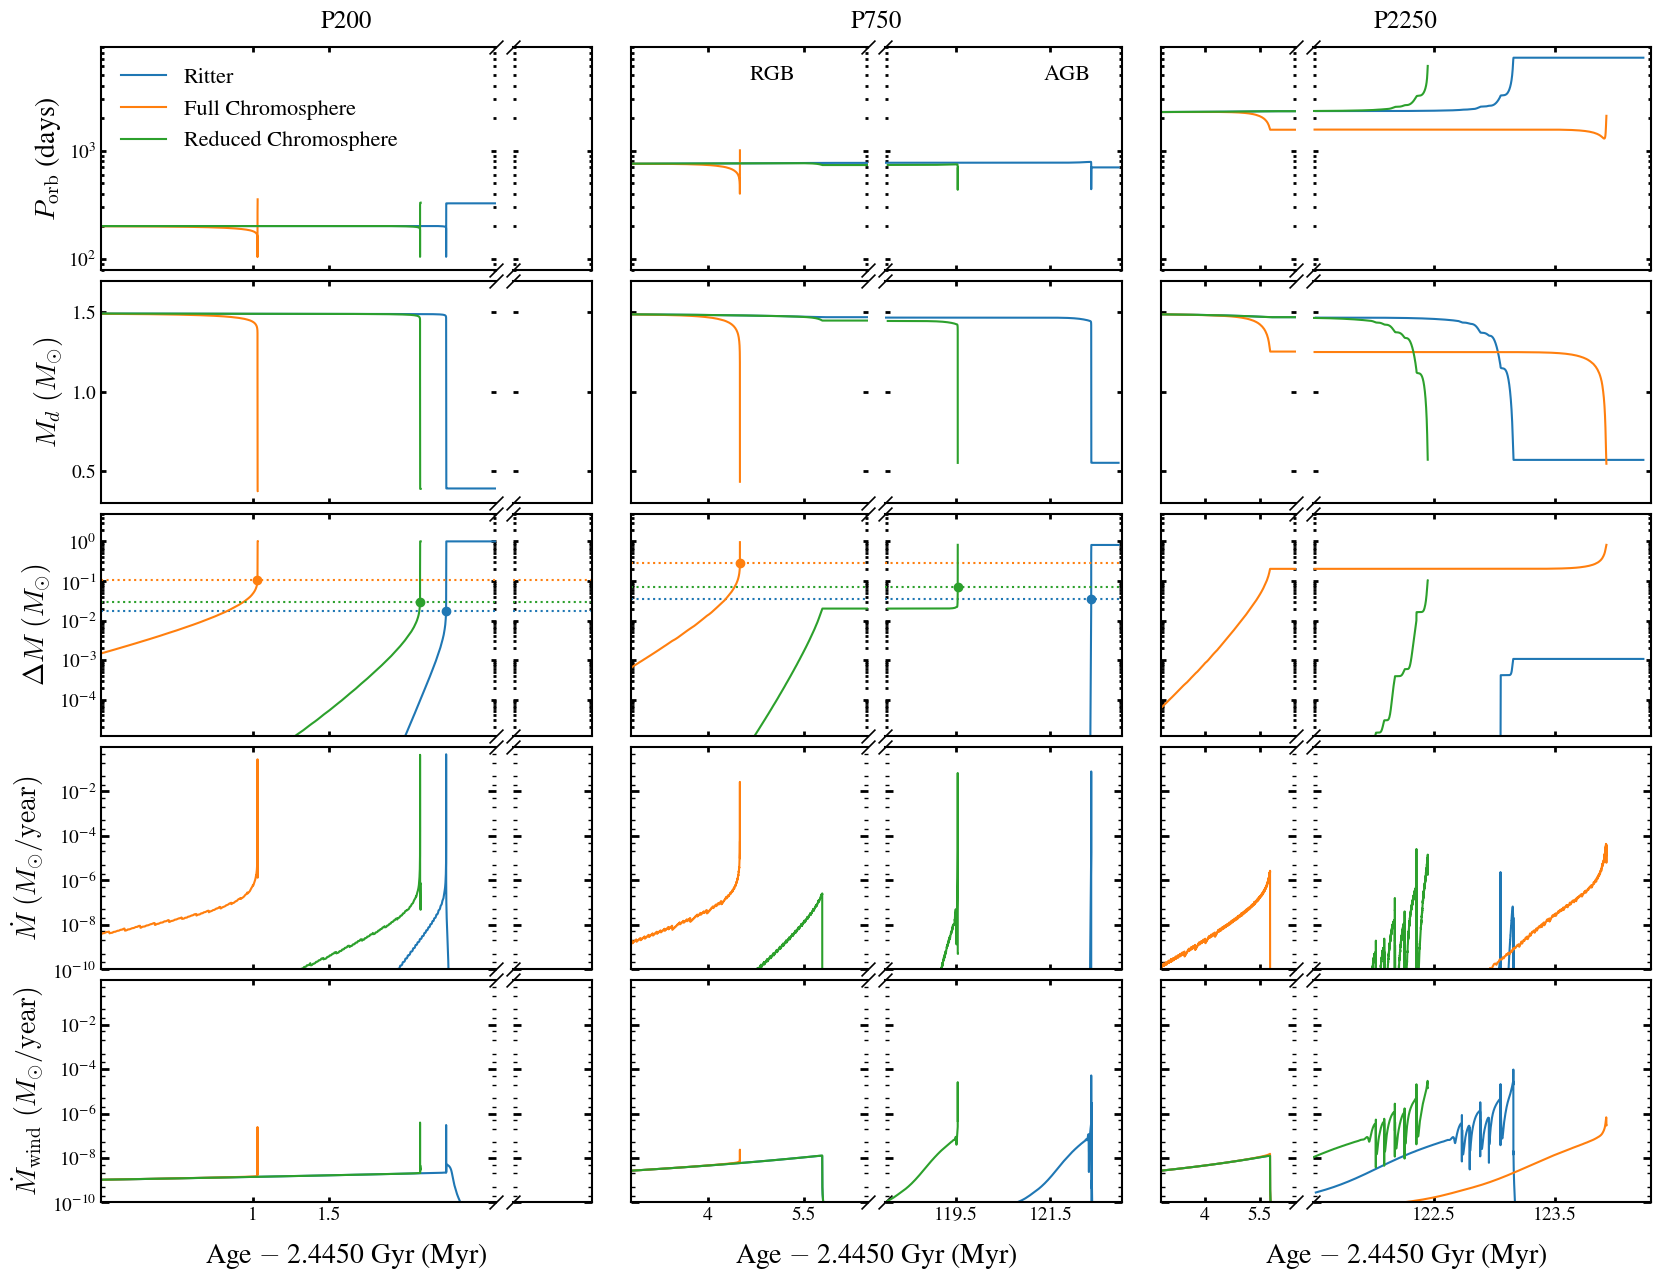

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import LogLocator, NullFormatter

Ncol = len(kolb_histories)
beta = 0.75

# Active rows:
# 0: orbital period
# 1: donor mass
# 2: transferred mass
# 3: mass-transfer rate
# 4: wind mass-loss rate
N = 5

fig = plt.figure(figsize=(20, 3 * N))
gs = GridSpec(nrows=N, ncols=Ncol, figure=fig, hspace=0.05, wspace=0.08)

age_norm = 1e9
max_mdot_epoch = 0.0

# Edit one sub-list per column to change the kink/broken x-axis ranges.
# Values are in Gyr. Each column can use different ranges and even a different
# number of broken-axis panels.

'''
x_ranges_gyr_by_col = [
    [(2.445, 2.4479), (2.563, 2.568)],  # column 0 / P200
    [(2.4478, 2.4500), (2.5651, 2.5655)],  # column 1 / P750
    [(2.4478, 2.4515), (2.5655, 2.567)],  # column 2 / P2000
]

# Edit one sub-list per column to set the visual axis proportions manually.
# The number of ratios must match the number of ranges in that column.
# Example: [2, 1] makes the left panel twice as wide as the right panel.
# Use None for a column to scale its panels by their x-range spans instead.
x_width_ratios_by_col = [
    [1.0, 0.2],  # column 0 / P200
    [1.0, 0.5],  # column 1 / P750
    [0.4, 1.0],  # column 2 / P2000
]
'''

# Plot the x-axis as time since the first plotted age, in Myr.
x_start_gyr = min(lo for ranges in x_ranges_gyr_by_col for lo, hi in ranges)
x_axis_label = rf'Age $-$ {x_start_gyr:.4f} Gyr (Myr)'
x_tick_steps_myr = [0.5, 0.2, 0.1, 0.05]
x_tick_count = 2
x_tick_edge_padding_frac = 0.05


sim_pers = ['P200', 'P750', 'P2250']


class KinkAxes(list):
    """List of axes plus the x-ranges used to create them."""

    def __init__(self, axes, x_ranges_gyr):
        super().__init__(axes)
        self.x_ranges_gyr = x_ranges_gyr
        self.has_plotted_data = [False for _ in axes]


def get_column_x_ranges_gyr(col):
    """Return and validate the broken x-axis ranges for one column."""
    if col >= len(x_ranges_gyr_by_col):
        raise ValueError(
            f"Missing x_ranges_gyr_by_col entry for column {col}. "
            f"Expected {Ncol} column entries."
        )

    x_ranges_gyr = x_ranges_gyr_by_col[col]
    if len(x_ranges_gyr) == 0:
        raise ValueError(f"x_ranges_gyr_by_col[{col}] must contain at least one range.")

    for lo, hi in x_ranges_gyr:
        if hi <= lo:
            raise ValueError(
                f"Invalid x range ({lo}, {hi}) in x_ranges_gyr_by_col[{col}]."
            )

    return x_ranges_gyr


def get_column_width_ratios(col, x_ranges_gyr):
    """Return and validate the visual width ratios for one column."""
    if col >= len(x_width_ratios_by_col):
        raise ValueError(
            f"Missing x_width_ratios_by_col entry for column {col}. "
            f"Expected {Ncol} column entries."
        )

    width_ratios = x_width_ratios_by_col[col]
    if width_ratios is None:
        return [hi - lo for lo, hi in x_ranges_gyr]

    if len(width_ratios) != len(x_ranges_gyr):
        raise ValueError(
            f"x_width_ratios_by_col[{col}] has {len(width_ratios)} ratios, "
            f"but x_ranges_gyr_by_col[{col}] has {len(x_ranges_gyr)} ranges."
        )

    for ratio in width_ratios:
        if ratio <= 0:
            raise ValueError(
                f"Invalid width ratio {ratio} in x_width_ratios_by_col[{col}]."
            )

    return width_ratios


def age_gyr_to_plot_myr(age_gyr):
    """Convert an absolute age in Gyr to Myr after x_start_gyr."""
    return (np.asarray(age_gyr) - x_start_gyr) * 1e3


def myr_tick_label(value):
    """Format Myr tick labels without distracting trailing zeros."""
    if np.isclose(value, round(value), atol=0.05):
        return f"{value:.0f}"

    return f"{value:.1f}"


def nearest_before_max_index(arr, val, tol):
    
    max_idx = max(range(len(arr)), key=lambda i: arr[i])

    if max_idx == 0:
        return -1

    idx = min(range(max_idx), key=lambda i: abs(arr[i] - val))

    if abs(arr[idx] - val) <= tol:
        return idx

    return -1


def make_kink_axes(row, col):
    """Create broken-x axes inside one GridSpec cell."""
    x_ranges_gyr = get_column_x_ranges_gyr(col)
    width_ratios = get_column_width_ratios(col, x_ranges_gyr)

    subgs = gs[row, col].subgridspec(
        1,
        len(x_ranges_gyr),
        width_ratios=width_ratios,
        wspace=0.07,
    )

    axes = []
    for j, (lo, hi) in enumerate(x_ranges_gyr):
        if j == 0:
            ax = fig.add_subplot(subgs[0, j])
        else:
            ax = fig.add_subplot(subgs[0, j], sharey=axes[0])

        ax.set_xlim(*age_gyr_to_plot_myr([lo, hi]))

        if j > 0:
            ax.spines["left"].set_visible(False)
            ax.tick_params(left=True, labelleft=False)

        if j < len(x_ranges_gyr) - 1:
            ax.spines["right"].set_visible(False)

        axes.append(ax)

    add_kink_marks(axes)
    return KinkAxes(axes, x_ranges_gyr)


def choose_good_xticks(lo, hi):
    """Choose up to two readable interior ticks in Myr."""
    lo_myr, hi_myr = age_gyr_to_plot_myr([lo, hi])
    span = hi_myr - lo_myr
    if span <= 0:
        return np.array([])

    inner_lo = lo_myr + x_tick_edge_padding_frac * span
    inner_hi = hi_myr - x_tick_edge_padding_frac * span

    for tick_step_myr in x_tick_steps_myr:
        first_tick = np.ceil(inner_lo / tick_step_myr) * tick_step_myr
        last_tick = np.floor(inner_hi / tick_step_myr) * tick_step_myr

        if first_tick > last_tick:
            continue

        candidates = np.arange(
            first_tick,
            last_tick + 0.5 * tick_step_myr,
            tick_step_myr,
        )

        if len(candidates) <= x_tick_count:
            return candidates

        targets = np.linspace(lo_myr, hi_myr, x_tick_count + 2)[1:-1]
        remaining = candidates.tolist()
        ticks = []
        for target in targets:
            nearest_index = min(
                range(len(remaining)),
                key=lambda index: abs(remaining[index] - target),
            )
            ticks.append(remaining.pop(nearest_index))

        return np.array(sorted(ticks))

    return np.array([(lo_myr + hi_myr) / 2.0])


def set_good_xticks(ax, lo, hi):
    """Set readable interior x ticks for one broken-axis panel."""
    ticks = choose_good_xticks(lo, hi)
    ax.set_xticks(ticks)
    ax.set_xticklabels([myr_tick_label(tick) for tick in ticks])


def set_data_aware_xticks(axes, histories=None):
    """Set x ticks only on broken-axis panels that contain data."""
    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        if axes.has_plotted_data[j]:
            set_good_xticks(ax, lo, hi)
        else:
            ax.set_xticks([])
            ax.set_xticklabels([])


def add_kink_marks(axes, marker_size=10):
    """Draw uniform diagonal kink marks between neighboring broken axes."""
    for left_ax, right_ax in zip(axes[:-1], axes[1:]):


        # right edge of left axis
        left_ax.plot(
            [1, 1],
            [0, 1],
            transform=left_ax.transAxes,
            marker=[(-1, -1), (1, 1)],
            markersize=marker_size,
            linestyle="none",
            color="k",
            mec="k",
            mew=1.2,
            clip_on=False,
        )

        # left edge of right axis
        right_ax.plot(
            [0, 0],
            [0, 1],
            transform=right_ax.transAxes,
            marker=[(-1, -1), (1, 1)],
            markersize=marker_size,
            linestyle="none",
            color="k",
            mec="k",
            mew=1.2,
            clip_on=False,
        )


def plot_kinked(axes, history, y, **kwargs):
    """Plot only the selected x-ranges on the broken axes."""
    x_gyr = (history.star_age.values - max_mdot_epoch) / age_norm
    x_myr = age_gyr_to_plot_myr(x_gyr)
    y = np.asarray(y)

    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        select = (x_gyr >= lo) & (x_gyr <= hi)
        finite_select = select & np.isfinite(y)
        if np.count_nonzero(finite_select) >= 2:
            axes.has_plotted_data[j] = True

        ax.plot(x_myr[select], y[select], **kwargs)


def plot_scatter(axes, x_raw, y, **kwargs):
    """Plot only the selected x-ranges on the broken axes."""
    x_gyr = (x_raw - max_mdot_epoch) / age_norm
    x_myr = age_gyr_to_plot_myr(x_gyr)
    y = np.asarray(y)

    for j, (ax, (lo, hi)) in enumerate(zip(axes, axes.x_ranges_gyr)):
        select = (x_gyr >= lo) & (x_gyr <= hi)
        finite_select = select & np.isfinite(y)
        if np.count_nonzero(finite_select) >= 1:
            axes.has_plotted_data[j] = True

        ax.scatter(x_myr[select], y[select], **kwargs)


def add_column_xlabel(row, col, xlabel):
    """Add one shared x-label under all kink axes in a column."""
    label_ax = fig.add_subplot(gs[row, col], frameon=False)
    label_ax.tick_params(
        labelcolor="none",
        top=False,
        bottom=False,
        left=False,
        right=False,
    )
    label_ax.set_xlabel(xlabel, fontsize=20, labelpad=10)



def add_column_title(row, col, title):
    """Add one shared title above all kink axes in a column."""
    title_ax = fig.add_subplot(gs[row, col], frameon=False)
    title_ax.tick_params(
        labelcolor="none",
        top=False,
        bottom=False,
        left=False,
        right=False,
    )
    title_ax.set_title(title, fontsize=18, pad=14)



def format_kinked_axes(
    axes,
    col_index,
    ylabel=None,
    xlabel=None,
    ylim=None,
    yscale=None,
    title=None,
    labelbottom=False,
):
    for j, ax in enumerate(axes):
        if ylim is not None:
            ax.set_ylim(*ylim)

        if yscale is not None:
            ax.set_yscale(yscale)

        ax.tick_params(
            which="both",
            direction="in",
            top=True,
            right=True,
            labelsize=14,
            labelbottom=labelbottom,
            width=2,
        )

        if col_index != 0 or j != 0:
            ax.tick_params(labelleft=False)

        if xlabel is not None:
            ax.set_xlabel(xlabel, fontsize=20)

    if ylabel is not None and col_index == 0:
        axes[0].set_ylabel(ylabel, fontsize=20)



def set_dense_log_yticks(axes):
    """Show roughly six major ticks plus minor ticks at 2 and 5 per decade."""
    # Broken-axis segments share their y-axis locators and formatters.
    axes[0].yaxis.set_major_locator(LogLocator(base=10, numticks=6))
    axes[0].yaxis.set_minor_locator(
        LogLocator(base=10, subs=(2, 5), numticks=100)
    )
    axes[0].yaxis.set_minor_formatter(NullFormatter())
    for ax in axes:
        ax.tick_params(axis="y", which="major", length=6)
        ax.tick_params(axis="y", which="minor", length=3, width=1)


# Row 0: orbital period
for i in range(Ncol):
    axes = make_kink_axes(0, i)

    if i==1:
        axes[0].text(age_gyr_to_plot_myr(2.44965), 4500, 'RGB', fontsize = 16)
        axes[1].text(age_gyr_to_plot_myr(2.56635), 4500, 'AGB', fontsize = 16)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C0",
        label = 'Ritter'
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C1",
        label = r'Full Chromosphere'
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        history.period_days.values,
        c="C2",
        label = r'Reduced Chromosphere'
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$P_{\rm orb}$ (days)',
        ylim=(80, 9000),
        yscale="log",
        title=r'{}'.format(sim_pers[i]),
        labelbottom=False,
    )

    add_column_title(0, i, r'{}'.format(sim_pers[i]))

    if i==0:
        axes[0].legend(loc = 'upper left', fontsize = 16, framealpha = 0.0)

'''
# Row 1: donor radius
for i in range(Ncol):
    axes = make_kink_axes(1, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        10**history.log_R.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        10**history.log_R.values,
        c="C1",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$R_d~(R_{\odot})$',
        ylim=(0, 450),
        labelbottom=False,
    )
'''

# Row 1: donor mass
for i in range(Ncol):
    axes = make_kink_axes(1, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C1",
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        history.star_1_mass.values,
        c="C2",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$M_d~(M_{\odot})$',
        ylim=(0.3, 1.7),
        labelbottom=False,
    )


# Row 2: cumulative transferred mass
for i in range(Ncol):
    axes = make_kink_axes(2, i)

    history = kolb_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    

    plot_kinked(
        axes,
        history,
        y,
        c="C0",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C0",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C0')
        axes[1].axhline(ce_y, linestyle = ':', c='C0')

    history = chrom_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)
    plot_kinked(
        axes,
        history,
        y,
        c="C1",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C1",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C1')
        axes[1].axhline(ce_y, linestyle = ':', c='C1')

    
    history = chrom_histories_0p5fcon[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)
    plot_kinked(
        axes,
        history,
        y,
        c="C2",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.005)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([y[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C2",
        )

        axes[0].axhline(ce_y, linestyle = ':', c='C2')
        axes[1].axhline(ce_y, linestyle = ':', c='C2')
    

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\Delta M~(M_{\odot})$',
        ylim=(1.2e-5, 5),
        yscale="log",
        labelbottom=False,
    )

'''
# Row 4: cumulative transferred carbon mass
for i in range(Ncol):
    axes = make_kink_axes(4, i)

    history = kolb_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    deltay = np.diff(y)
    deltamc = np.diff(y) * (history.surface_c12.values[1:]+history.surface_c12.values[:-1])/2.0
    cmass_transferred = np.cumsum(deltamc)
    cmass_transferred = np.array([0] + cmass_transferred.tolist())

    plot_kinked(
        axes,
        history,
        cmass_transferred,
        c="C0",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.01)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([cmass_transferred[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C0",
        )

    history = chrom_histories[i]
    y = (history.star_2_mass.values - history.star_2_mass.values[0]) / (1 - beta)

    deltay = np.diff(y)
    deltamc = np.diff(y) * (history.surface_c12.values[1:]+history.surface_c12.values[:-1])/2.0
    cmass_transferred = np.cumsum(deltamc)
    cmass_transferred = np.array([0] + cmass_transferred.tolist())

    plot_kinked(
        axes,
        history,
        cmass_transferred,
        c="C1",
    )

    rstar_by_rl = 10**history.log_R.values/history.rl_1.values
    #ce_index = nearest_before_max_index(history.lg_mtransfer_rate.values, -2, 0.1)
    ce_index = nearest_before_max_index(rstar_by_rl, 0.99, 0.01)
    ce_age = np.array([history.star_age.values[ce_index]])
    ce_y = np.array([cmass_transferred[ce_index]])

    if ce_index>0:

        plot_scatter(
            axes,
            ce_age,
            ce_y,
            c="C1",
        )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\Delta M_{\rm C12}~(M_{\odot})$',
        ylim=(2e-7, 0.01),
        yscale="log",
        labelbottom=False,
    )
'''


# Row 3: mass-transfer rate
for i in range(Ncol):
    axes = make_kink_axes(3, i)

    history = kolb_histories[i]
    plot_kinked(
        axes,
        history,
        10.0 ** history.lg_mtransfer_rate.values,
        c="C0",
    )

    history = chrom_histories[i]
    plot_kinked(
        axes,
        history,
        10.0 ** history.lg_mtransfer_rate.values,
        c="C1",
    )

    history = chrom_histories_0p5fcon[i]
    plot_kinked(
        axes,
        history,
        10.0 ** history.lg_mtransfer_rate.values,
        c="C2",
    )

    set_data_aware_xticks(axes, [kolb_histories[i], chrom_histories[i]])

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\dot{M}~(M_{\odot}/{\rm year})$',
        #xlabel=x_axis_label,
        ylim=(1e-10, 0.9999),
        yscale="log",
        labelbottom=False,
    )
    set_dense_log_yticks(axes)


# Row 4: donor wind mass-loss rate
# Convert log10 wind rates to Msun/yr for the logarithmic y-axis.
for i in range(Ncol):
    axes = make_kink_axes(4, i)

    for histories, color in (
        (kolb_histories, "C0"),
        (chrom_histories, "C1"),
        (chrom_histories_0p5fcon, "C2"),
    ):
        history = histories[i]
        plot_kinked(
            axes,
            history,
            10.0 ** history.lg_wind_mdot_1.values,
            c=color,
        )

    set_data_aware_xticks(axes)

    format_kinked_axes(
        axes,
        i,
        ylabel=r'$\dot{M}_{\rm wind}~(M_{\odot}/{\rm year})$',
        ylim=(1e-10, 0.9999),
        yscale="log",
        labelbottom=True,
    )
    set_dense_log_yticks(axes)

    add_column_xlabel(4, i, x_axis_label)

#plt.show()

# Optional save:
plt.savefig("./chromosphere_figs/quants_v_age_revised.png", dpi=200, bbox_inches="tight")


In [8]:
x_ranges_gyr_by_col = [
    [(2.445, 2.4476), (2.563, 2.568)],  # column 0 / P200
    [(2.4478, 2.4515), (2.563, 2.568)],  # column 1 / P750
    [(2.4478, 2.4515), (2.5665, 2.5693)],  # column 2 / P2000
]

# Edit one sub-list per column to set the visual axis proportions manually.
# The number of ratios must match the number of ranges in that column.
# Example: [2, 1] makes the left panel twice as wide as the right panel.
# Use None for a column to scale its panels by their x-range spans instead.
x_width_ratios_by_col = [
    [1.0, 0.2],  # column 0 / P200
    [1.0, 1.0],  # column 1 / P750
    [0.4, 1.0],  # column 2 / P2000
]

## WD+MS using CEE

In [2]:
def post_CE_calc(Ebind, Mcore, Macc, Mdon, sma, alpha=0.3,
                 unb_env_cons_qty='energy'):

    scalar_input = np.isscalar(Ebind) and np.isscalar(Mcore) and np.isscalar(Macc) and np.isscalar(Mdon) and np.isscalar(sma)

    Ebind = np.atleast_1d(Ebind).astype(float)
    Mcore = np.atleast_1d(Mcore).astype(float)
    Macc = np.atleast_1d(Macc).astype(float)
    Mdon = np.atleast_1d(Mdon).astype(float)
    sma = np.atleast_1d(sma).astype(float)

    select_bound = Ebind < 0.0

    orb_en_init = -1.0 * G * (Macc * msun) * (Mdon * msun) / (2.0 * sma * rsun)
    orb_en_final = (Ebind / alpha) + orb_en_init

    sma_final = np.zeros_like(sma, dtype=float)

    sma_final[select_bound] = (
        -1.0 * G * (Mcore[select_bound] * msun) * (Macc[select_bound] * msun)
        / (2.0 * orb_en_final[select_bound])
    )

    if unb_env_cons_qty == 'sma':
        sma_final[~select_bound] = sma[~select_bound] * rsun
    else:
        sma_final[~select_bound] = (
            -1.0 * G * (Mcore[~select_bound] * msun) * (Macc[~select_bound] * msun)
            / (2.0 * orb_en_init[~select_bound])
        )

    P_sec = 2 * np.pi * np.sqrt(sma_final**3 / (G * (Macc + Mcore) * msun))
    P_day = P_sec / 86400.0

    sma_final = sma_final / rsun

    if scalar_input:
        return float(sma_final[0]), float(P_day[0])

    return sma_final, P_day

In [17]:
history_chrom_wdmsce = pd.read_csv('./chromosphere_accretion_3/LOGS1_2.5m1_0.8m2_3200p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi/history.data', skiprows = 5, delim_whitespace=True)
#history_chrom_wdmsce = pd.read_csv('./chromosphere_accretion_4/LOGS1_2.3m1_0.8m2_3000p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_revised/history.data', skiprows = 5, delim_whitespace=True)
history_ritter_wdmsce = pd.read_csv('./chromosphere_accretion_3/LOGS1_2.5m1_0.8m2_3200p_0.75beta_0.0delta_0.0gamma_acclim1e-3_newacc_temmink_yamaguchi_mlt1.9_withmoi_kolbrevised/history.data', skiprows = 5, delim_whitespace=True)



In [18]:
window_high = 3e6
window_low = 7.12e8

max_mdot_epoch_chrom = history_chrom_wdmsce.star_age.values[np.argmax(history_chrom_wdmsce.lg_mtransfer_rate)]
select = (history_chrom_wdmsce.star_age<(max_mdot_epoch_chrom+window_high)) & (history_chrom_wdmsce.star_age>(window_low))
history_chrom_wdmsce = history_chrom_wdmsce[select]

max_mdot_epoch_ritter = history_ritter_wdmsce.star_age.values[np.argmax(history_ritter_wdmsce.lg_mtransfer_rate)]
select = (history_ritter_wdmsce.star_age<(max_mdot_epoch_chrom+window_high)) & (history_ritter_wdmsce.star_age>(window_low))
history_ritter_wdmsce = history_ritter_wdmsce[select]






mcore = history_chrom_wdmsce.he_core_mass.values
mdon = history_chrom_wdmsce.star_1_mass.values
macc = history_chrom_wdmsce.star_2_mass.values
sma = history_chrom_wdmsce.binary_separation.values

env_int_energy = history_chrom_wdmsce.energy_env.values
env_int_thermal_energy = history_chrom_wdmsce.egas_from_Pgas_env.values + history_chrom_wdmsce.erad_from_Prad_env.values
env_int_recomb_energy = env_int_energy - env_int_thermal_energy

alpha_th = 1.0
alpha_recomb = 0.0

env_tot_chrom_low = history_chrom_wdmsce.egrav_env.values + alpha_th*env_int_thermal_energy + alpha_recomb*env_int_recomb_energy

alpha_th = 1.0
alpha_recomb = 1.0

env_tot_chrom_high = history_chrom_wdmsce.egrav_env.values + alpha_th*env_int_thermal_energy + alpha_recomb*env_int_recomb_energy

In [15]:
print(len(history_ritter_wdmsce))

19943


3207.8747590457347
22.39911582552831 825.0534053015567
22.39911582552831 2049.3668258996986
1.045630585274438
0.591515190505994
-1.5283990315583773


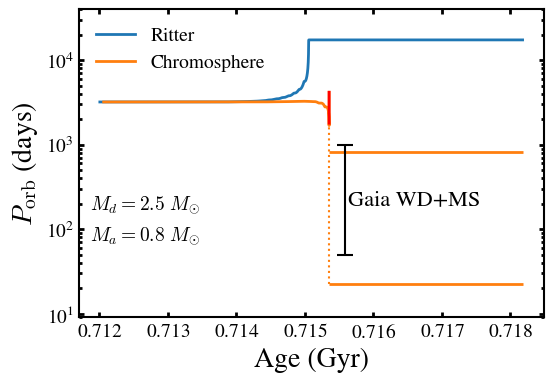

In [19]:
N = 1
beta = 0.75

fig = plt.figure(figsize=(6, 4 * N))
gs = GridSpec(nrows=N, ncols=1, figure=fig, hspace=0.05, wspace=0.08)

#ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[0])


y_ritter = (history_ritter_wdmsce.star_2_mass.values - history_ritter_wdmsce.star_2_mass.values[0]) / (1 - beta)
#ax0.plot(history_ritter_wdmsce.star_age.values, y_ritter)
y_chrom = (history_chrom_wdmsce.star_2_mass.values - history_chrom_wdmsce.star_2_mass.values[0]) / (1 - beta)
#ax0.plot(history_chrom_wdmsce.star_age.values, y_chrom)
#ax0.set_yscale('log')


ax1.plot(history_ritter_wdmsce.star_age.values/1e9, history_ritter_wdmsce.period_days.values, linewidth = 2, c = 'C0',
         label = 'Ritter')
ax1.plot(history_chrom_wdmsce.star_age.values/1e9, history_chrom_wdmsce.period_days.values, linewidth = 2, c = 'C1',
         label = 'Chromosphere')


print(history_ritter_wdmsce.period_days.values[0])

history_chrom_wdmsce_before = history_chrom_wdmsce[history_chrom_wdmsce.star_age<max_mdot_epoch_chrom]
cee_epoch_index = np.argmin(np.abs(history_chrom_wdmsce_before.lg_mtransfer_rate - 0.031622))
cee_epoch = history_chrom_wdmsce_before.star_age.values[cee_epoch_index]
cee_epoch_period = history_chrom_wdmsce_before.period_days.values[cee_epoch_index]
y_cee_epoch = ((history_chrom_wdmsce_before.star_2_mass.values - history_chrom_wdmsce_before.star_2_mass.values[0]) / (1 - beta))[cee_epoch_index]

sma_final_low, final_period_low = post_CE_calc(env_tot_chrom_low[cee_epoch_index], mcore[cee_epoch_index], 
                                               macc[cee_epoch_index], mdon[cee_epoch_index], sma[cee_epoch_index],
                                               unb_env_cons_qty = 'energy')

sma_final_high, final_period_high = post_CE_calc(env_tot_chrom_high[cee_epoch_index], mcore[cee_epoch_index], 
                                               macc[cee_epoch_index], mdon[cee_epoch_index], sma[cee_epoch_index],
                                               unb_env_cons_qty = 'energy')

sma_final_low_sma, final_period_low_sma = post_CE_calc(env_tot_chrom_low[cee_epoch_index], mcore[cee_epoch_index], 
                                               macc[cee_epoch_index], mdon[cee_epoch_index], sma[cee_epoch_index],
                                               unb_env_cons_qty = 'sma')

sma_final_high_sma, final_period_high_sma = post_CE_calc(env_tot_chrom_high[cee_epoch_index], mcore[cee_epoch_index], 
                                               macc[cee_epoch_index], mdon[cee_epoch_index], sma[cee_epoch_index],
                                               unb_env_cons_qty = 'sma')

#ax0.scatter(cee_epoch, y_cee_epoch, marker = 'x', s = 50, c='C1')
#ax1.scatter(cee_epoch/1e9, cee_epoch_period, marker = 'x', s = 70, c='red', zorder = 100)

select_post_cee = history_chrom_wdmsce.star_age.values>cee_epoch
ax1.plot(history_chrom_wdmsce.star_age.values[select_post_cee]/1e9, history_chrom_wdmsce.period_days.values[select_post_cee], linewidth = 2, c = 'red')

print(final_period_low, final_period_high)
print(final_period_low_sma, final_period_high_sma)
print(history_chrom_wdmsce_before.star_2_mass.values[cee_epoch_index])
print(history_chrom_wdmsce_before.he_core_mass.values[cee_epoch_index])
print(history_chrom_wdmsce_before.log_abs_mdot.values[cee_epoch_index])

x_start = cee_epoch/1e9
x_end = max(history_ritter_wdmsce.star_age.values/1e9)
y = final_period_low
ax1.hlines(y=y, xmin=x_start, xmax=x_end, color="C1", linestyle="-", linewidth = 2)
y = final_period_low_sma
#ax1.hlines(y=y, xmin=x_start, xmax=x_end, color="C1", linestyle="--", linewidth = 2)

x_start = cee_epoch/1e9
x_end = max(history_ritter_wdmsce.star_age.values/1e9)
y = final_period_high
ax1.hlines(y=y, xmin=x_start, xmax=x_end, color="C1", linestyle="-", linewidth = 2)
y = final_period_high_sma
#ax1.hlines(y=y, xmin=x_start, xmax=x_end, color="C1", linestyle="--", linewidth = 2)

#ax0.set_ylim(1e-6, 2)

ax1.tick_params(which='both',direction='in',top=True,right=True,labelsize=14,labelbottom = True, width=2,
                       labelleft = True)
ax1.set_xlabel(r'Age (Gyr)', fontsize = 20)
ax1.set_ylabel(r'$P_{\rm orb}$ (days)', fontsize = 20)

ax1.legend(loc = 'upper left', ncols = 1, framealpha = 0, fontsize = 14)

ax1.set_ylim(9, 4e4)
#ax1.set_ylim(1, 5000)

#ax1.text(1.1645, 1400, r'$\alpha_{\rm rec}=1.0$', c='C1', fontsize = 16)
#ax1.text(1.1645, 70, r'$\alpha_{\rm rec}=0.0$', c='C1', fontsize = 16)



#y_low, y_high = sorted([final_period_low, final_period_high])
y_low = 50
y_high = 1000

ax1.vlines(
    x=cee_epoch / 1e9,
    ymin=final_period_low,
    ymax=cee_epoch_period - 100,
    color="C1",
    linestyle=":",
    linewidth=1.5,
    zorder=150,
)

x_arrow = cee_epoch/1e9 + 0.08 * (x_end - x_start)
y_mid = np.sqrt(y_low * y_high)  # visually centered on a log y-axis

ax1.errorbar(
    x_arrow,
    y_mid,
    yerr=[[y_mid - y_low], [y_high - y_mid]],
    fmt="none",
    ecolor="black",
    elinewidth=1.5,
    capsize=6,
    capthick=1.5,
    zorder=200,
)

ax1.text(
    x_arrow + 0.02 * (x_end - x_start),
    y_mid,
    "Gaia WD+MS",
    color="black",
    fontsize=16,
    va="center",
    ha="left",
)

ax1.text(0.025, 0.35, r'$M_d=2.5~M_{\odot}$', transform=ax1.transAxes, fontsize = 14)
ax1.text(0.025, 0.25, r'$M_a=0.8~M_{\odot}$', transform=ax1.transAxes, fontsize = 14)

ax1.set_yscale('log')

plt.savefig("./chromosphere_figs/gaia_wdms_from_cee_revised.png", dpi=200, bbox_inches="tight")


In [11]:
history_ritter_wdmsce.star_2_mass.values

array([], dtype=float64)